# Fixed LightGBM blends and study robustness

**historical_hypothetical_unit_scenario**. B50 is predeclared, not selected from outer outcomes. Previously inspected folds and unverified unit adjustments prohibit independent-validation or certified-physical-prediction claims. No prior experiment is rerun.

## 1. Setup, protected files and frozen plan

In [1]:
import json, sys
from pathlib import Path
from unittest.mock import patch
from IPython.display import display, Markdown, SVG
ROOT=Path.cwd();OUT=ROOT/'blending_outputs'
sys.dont_write_bytecode=True
sys.path.insert(0,str(OUT/'source'));sys.path.insert(0,str(OUT/'tests'))
fit_guard=patch('lightgbm.LGBMRegressor.fit',side_effect=AssertionError('New LightGBM fits are forbidden in this zero-fit analysis'))
blocked_fit=fit_guard.start()
from blend import Analysis, SCENARIO
from reporting import make_figures, compose_report
from test_blending import run_suite
analysis=Analysis(OUT)
print('Repository:',ROOT,'Scenario:',SCENARIO)
print((OUT/'predeclared_plan.json').read_text())
print((OUT/'environment.json').read_text())
print('Protected paths:',len(json.loads((OUT/'integrity_manifest.json').read_text())['before']))

Repository: /Users/gourabadhikari/Desktop/marine-microplastics-baseline Scenario: historical_hypothetical_unit_scenario
{
  "scenario": "historical_hypothetical_unit_scenario",
  "weights_optimized": {
    "B0": 0.0,
    "B25": 0.25,
    "B50": 0.5,
    "B75": 0.75,
    "B100": 1.0
  },
  "main_candidate": "B50",
  "prediction_scale": "log10(concentration + 0.001)",
  "gate": {
    "max_R2_loss": 0.015,
    "max_study_macro_MAE_increase": 0.0,
    "min_improvements_of_MAE_p90_coverage": 2,
    "max_worst_study_MAE_increase": 0.1
  },
  "stage_c": {
    "outer_folds": 5,
    "inner_folds": 3,
    "inner_inner_folds": 3,
    "candidates": 8,
    "hard_fit_cap": 100,
    "objective": "Minimize study-macro MAE among weights with pooled inner R2 within 0.015 of maximum; exact ties to B50 then smaller optimized weight. Training-only, nested optimized-procedure selection; never use outer labels.",
    "budget_policy": "Calculate full upper bound before any fit; skip if over 100. Do not reduce

## 2. Read-only artifacts, exact row alignment and original target reconstruction

In [2]:
display(analysis.load())
print('All original OOF rows, targets, folds and study identities verified.')
print('Input files:',json.dumps(analysis.input_hashes,indent=2))
print('No LightGBM fitting:',blocked_fit.call_count==0)

29,076 records, 96 accessions, 68 organisations
16,988 records, 73 accessions, 73 publications, 72 studies, 52 organisations


,water_row,source_row,study,doi,accession,fold,target_log10,original_prediction_log10,optimized_prediction_log10,method_family,study_size,study_size_bin,selected_candidate,scenario
0,0,0,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.128217,-2.451774,-2.762704,surface net,6135,1001+,C7_fewer_trees,historical_hypothetical_unit_scenario
1,1,1,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-0.830126,-2.485834,-2.767258,surface net,6135,1001+,C7_fewer_trees,historical_hypothetical_unit_scenario
2,2,2,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.928118,-2.485834,-2.767258,surface net,6135,1001+,C7_fewer_trees,historical_hypothetical_unit_scenario
3,3,3,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.423474,-2.473610,-2.762704,surface net,6135,1001+,C7_fewer_trees,historical_hypothetical_unit_scenario
4,4,4,https://doi.org/10.1126/science.1192321,https://doi.org/10.1126/science.1192321,211007,1,-1.606249,-2.473610,-2.762704,surface net,6135,1001+,C7_fewer_trees,historical_hypothetical_unit_scenario


All original OOF rows, targets, folds and study identities verified.
Input files: {
  "reproduction_outputs/out_of_fold_predictions.csv": "f35e85d5d6b4291e846806a554b2f09000fc459357667e7b0ff0720a68ea512c",
  "reproduction_outputs/summary.json": "2dd7fedf7d308a28a8d18a433b0404c4ca111a9ad79a4ee4d75d0ab0efdfb54e",
  "reproduction_outputs/fold_metrics.csv": "53a89427c800addc5e93c39519002890b5642e555ec675211da8dd6d1041500d",
  "reproduction_outputs/model_parameters.json": "f7562e973bb969c8c366fdbed5289fb3376ba7cc4a8230d1dd14e75eb2a18e1b",
  "reproduction_outputs/unit_adjustments.json": "fedf38beb74a639b7123fdd19d1172c28df0a8128f9bb173942f39ad35819550",
  "reproduction_outputs/input_hashes.json": "976f2255e8241c4d97415f620d546c0a26a69e973b11296e3c32cfde7ec23147",
  "optimization_outputs/optimized_oof_predictions.csv": "6bca068021726017c8581223ef98f2ae89017965cc03a8851ff10919776816bf",
  "optimization_outputs/optimization_summary.json": "38f41a2ffff0c2dee4a280a507b262c04354d0411b7a356f1f15cf8

## 3. Stage A: five fixed target-free blends and reference metric reproduction

In [3]:
display(analysis.evaluate())
import pandas as pd
display(pd.read_csv(OUT/'reference_metric_audit.csv'))
print('B50 is the predetermined main candidate; no outer-score weight search.')

,blend,weight_optimized,rows,studies,scenario,R2,MAE,RMSE,study_macro_MAE,study_macro_MSE,...,delta_vs_B100__R2,delta_vs_B100__MAE,delta_vs_B100__RMSE,delta_vs_B100__study_macro_MAE,delta_vs_B100__study_macro_MSE,delta_vs_B100__median_study_MAE,delta_vs_B100__p90_study_MAE,delta_vs_B100__worst_study_MAE,delta_vs_B100__within_1_log,delta_vs_B100__mean_fold_R2
0,B0,0.00,16988,72,historical_hypothetical_unit_scenario,0.472631,0.996377,1.418198,1.060942,2.171751,...,-0.030750,-0.012965,0.041968,0.059531,0.141676,0.035222,-0.087826,-0.351901,0.029315,0.009441
1,B25,0.25,16988,72,historical_hypothetical_unit_scenario,0.489557,0.992965,1.395253,1.035630,2.093719,...,-0.013824,-0.016378,0.019023,0.034219,0.063644,0.019966,-0.199621,-0.263926,0.022722,0.029870
2,B50,0.50,16988,72,historical_hypothetical_unit_scenario,0.500325,0.994331,1.380459,1.016215,2.044096,...,-0.003057,-0.015011,0.004229,0.014804,0.014021,0.022242,-0.109910,-0.175951,0.020308,0.035107
3,B75,0.75,16988,72,historical_hypothetical_unit_scenario,0.504933,0.999807,1.374079,1.003910,2.022881,...,0.001551,-0.009535,-0.002151,0.002499,-0.007194,0.028833,-0.011652,-0.087975,0.009536,0.025150
4,B100,1.00,16988,72,historical_hypothetical_unit_scenario,0.503381,1.009343,1.376230,1.001411,2.030075,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


,blend,metric,recomputed,reference,difference
0,B0,R2,0.472631,0.472631,0.0
1,B0,MAE,0.996377,0.996377,0.0
2,B0,RMSE,1.418198,1.418198,0.0
3,B0,study_macro_MAE,1.060942,1.060942,0.0
4,B0,study_macro_MSE,2.171751,2.171751,0.0
5,B0,median_study_MAE,0.866895,0.866895,0.0
6,B0,p90_study_MAE,1.813391,1.813391,0.0
7,B0,worst_study_MAE,4.943935,4.943935,0.0
8,B0,within_1_log,0.639393,0.639393,0.0
9,B0,mean_fold_R2,-0.071235,-0.071235,0.0


B50 is the predetermined main candidate; no outer-score weight search.


## 4. Per-fold, per-study and post-hoc robustness diagnostics

In [4]:
display(analysis.fold[['fold','blend','rows','studies','R2','MAE','RMSE']])
display(pd.read_csv(OUT/'folds_2_and_5_diagnostic.csv'))
display(pd.read_csv(OUT/'prior_14_harmed_studies_diagnostic.csv'))
display(analysis.subgroups)
print('Every study retained, including the smallest groups; prior harms are diagnostics only.')

,fold,blend,rows,studies,R2,MAE,RMSE
0,1,B0,6135,1,-0.555996,0.727919,0.909012
1,1,B25,6135,1,-0.522616,0.721560,0.899209
2,1,B50,6135,1,-0.501875,0.718445,0.893063
3,1,B75,6135,1,-0.493770,0.717838,0.890650
4,1,B100,6135,1,-0.498304,0.719173,0.892001
5,2,B0,2714,11,0.003502,0.812758,1.003800
6,2,B25,2714,11,-0.079662,0.853168,1.044847
7,2,B50,2714,11,-0.186045,0.898582,1.095115
8,2,B75,2714,11,-0.315649,0.947995,1.153398
9,2,B100,2714,11,-0.468474,1.002473,1.218546


,fold,blend,rows,studies,scenario,R2,MAE,RMSE,study_macro_MAE,study_macro_MSE,...,delta_vs_B0__within_1_log,delta_vs_B100__R2,delta_vs_B100__MAE,delta_vs_B100__RMSE,delta_vs_B100__study_macro_MAE,delta_vs_B100__study_macro_MSE,delta_vs_B100__median_study_MAE,delta_vs_B100__p90_study_MAE,delta_vs_B100__worst_study_MAE,delta_vs_B100__within_1_log
0,2,B0,2714,11,historical_hypothetical_unit_scenario,0.003502,0.812758,1.003800,0.866409,1.174760,...,0.000000,0.471975,-0.189714,-0.214746,0.092871,0.165421,0.229538,0.014589,0.301305,0.155122
1,2,B25,2714,11,historical_hypothetical_unit_scenario,-0.079662,0.853168,1.044847,0.837261,1.109798,...,-0.038688,0.388812,-0.149305,-0.173699,0.063723,0.100459,0.212379,-0.037595,0.215035,0.116433
2,2,B50,2714,11,historical_hypothetical_unit_scenario,-0.186045,0.898582,1.095115,0.811354,1.060574,...,-0.071850,0.282428,-0.103891,-0.123432,0.037816,0.051235,0.112537,-0.089779,0.128766,0.083272
3,2,B75,2714,11,historical_hypothetical_unit_scenario,-0.315649,0.947995,1.153398,0.788870,1.027087,...,-0.119749,0.152824,-0.054478,-0.065149,0.015332,0.017749,0.012696,-0.043690,0.042496,0.035372
4,2,B100,2714,11,historical_hypothetical_unit_scenario,-0.468474,1.002473,1.218546,0.773538,1.009339,...,-0.155122,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,5,B0,2713,20,historical_hypothetical_unit_scenario,0.332296,0.901872,1.234621,1.044245,2.384314,...,0.000000,0.137486,-0.125935,-0.121164,-0.095566,-0.472979,-0.172771,-0.315388,-0.351901,0.072982
6,5,B25,2713,20,historical_hypothetical_unit_scenario,0.311344,0.923882,1.253841,1.052844,2.461525,...,-0.011795,0.116534,-0.103925,-0.101943,-0.086967,-0.395767,-0.246941,-0.228057,-0.263926,0.061187
7,5,B50,2713,20,historical_hypothetical_unit_scenario,0.281446,0.953089,1.280770,1.071409,2.566092,...,-0.023959,0.086636,-0.074718,-0.075014,-0.068402,-0.291200,-0.180893,-0.137380,-0.175951,0.049023
8,5,B75,2713,20,historical_hypothetical_unit_scenario,0.242601,0.988033,1.314933,1.100708,2.698015,...,-0.046812,0.047791,-0.039774,-0.040851,-0.039103,-0.159278,-0.097800,-0.030841,-0.087975,0.026170
9,5,B100,2713,20,historical_hypothetical_unit_scenario,0.194810,1.027807,1.355784,1.139811,2.857292,...,-0.072982,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


,study,fold,rows,blend,scenario,prior_harmed_diagnostic_only,MAE,MSE,RMSE,within_1_log,delta_vs_B0__MAE,delta_vs_B0__MSE,delta_vs_B0__RMSE,delta_vs_B0__within_1_log,delta_vs_B100__MAE,delta_vs_B100__MSE,delta_vs_B100__RMSE,delta_vs_B100__within_1_log
0,https://doi.org/10.1016/j.chemosphere.2022.133980,4,69,B0,historical_hypothetical_unit_scenario,True,0.169873,0.044820,0.211707,1.000000,0.000000,0.000000,0.000000,0.000000,-0.530828,-0.479961,-0.512710,0.086957
1,https://doi.org/10.1016/j.chemosphere.2022.133980,4,69,B25,historical_hypothetical_unit_scenario,True,0.265760,0.096260,0.310258,1.000000,0.095887,0.051440,0.098551,0.000000,-0.434941,-0.428521,-0.414160,0.086957
2,https://doi.org/10.1016/j.chemosphere.2022.133980,4,69,B50,historical_hypothetical_unit_scenario,True,0.400182,0.193400,0.439773,1.000000,0.230308,0.148580,0.228066,0.000000,-0.300519,-0.331381,-0.284645,0.086957
3,https://doi.org/10.1016/j.chemosphere.2022.133980,4,69,B75,historical_hypothetical_unit_scenario,True,0.549719,0.336240,0.579862,1.000000,0.379846,0.291421,0.368155,0.000000,-0.150982,-0.188540,-0.144555,0.086957
4,https://doi.org/10.1016/j.chemosphere.2022.133980,4,69,B100,historical_hypothetical_unit_scenario,True,0.700701,0.524781,0.724418,0.913043,0.530828,0.479961,0.512710,-0.086957,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,https://doi.org/10.3389/fmars.2021.626026,5,54,B0,historical_hypothetical_unit_scenario,True,0.850583,1.088718,1.043417,0.592593,0.000000,0.000000,0.000000,0.000000,-0.212321,-0.397724,-0.175781,0.129630
66,https://doi.org/10.3389/fmars.2021.626026,5,54,B25,historical_hypothetical_unit_scenario,True,0.891250,1.169738,1.081544,0.574074,0.040667,0.081019,0.038127,-0.018519,-0.171653,-0.316705,-0.137654,0.111111
67,https://doi.org/10.3389/fmars.2021.626026,5,54,B50,historical_hypothetical_unit_scenario,True,0.941432,1.263031,1.123847,0.537037,0.090849,0.174313,0.080430,-0.055556,-0.121472,-0.223411,-0.095351,0.074074
68,https://doi.org/10.3389/fmars.2021.626026,5,54,B75,historical_hypothetical_unit_scenario,True,0.999839,1.368600,1.169872,0.500000,0.149256,0.279881,0.126455,-0.092593,-0.063065,-0.117843,-0.049326,0.037037


,grouping,group,blend,rows,studies,scenario,R2,MAE,RMSE,study_macro_MAE,...,delta_vs_B0__within_1_log,delta_vs_B100__R2,delta_vs_B100__MAE,delta_vs_B100__RMSE,delta_vs_B100__study_macro_MAE,delta_vs_B100__study_macro_MSE,delta_vs_B100__median_study_MAE,delta_vs_B100__p90_study_MAE,delta_vs_B100__worst_study_MAE,delta_vs_B100__within_1_log
0,method_family,bulk water,B0,1903,12,historical_hypothetical_unit_scenario,-0.041714,2.053115,2.727677,1.383764,...,0.000000,-0.044366,-0.108160,0.058717,-0.129420,-0.477810,-0.395005,-0.626301,-0.065635,0.115081
1,method_family,bulk water,B25,1903,12,historical_hypothetical_unit_scenario,-0.021243,2.068740,2.700743,1.400370,...,-0.037310,-0.023895,-0.092535,0.031783,-0.112814,-0.444791,-0.342331,-0.471512,-0.049226,0.077772
2,method_family,bulk water,B50,1903,12,historical_hypothetical_unit_scenario,-0.007025,2.092728,2.681877,1.424680,...,-0.064635,-0.009677,-0.068547,0.012917,-0.088504,-0.354150,-0.216878,-0.314592,-0.032817,0.050447
3,method_family,bulk water,B75,1903,12,historical_hypothetical_unit_scenario,0.000940,2.122756,2.671250,1.457634,...,-0.089858,-0.001712,-0.038519,0.002290,-0.055550,-0.205887,-0.143438,-0.157413,-0.016409,0.025223
4,method_family,bulk water,B100,1903,12,historical_hypothetical_unit_scenario,0.002652,2.161275,2.668960,1.513184,...,-0.115081,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,method_family,pump,B0,852,6,historical_hypothetical_unit_scenario,-1.331179,1.299307,1.552286,1.228086,...,0.000000,-0.688936,0.264500,0.249411,0.050661,0.214858,0.093075,0.083983,0.292852,-0.206573
6,method_family,pump,B25,852,6,historical_hypothetical_unit_scenario,-1.101592,1.227562,1.473866,1.203475,...,0.031690,-0.459350,0.192756,0.170992,0.026050,0.107960,0.037235,0.002756,0.215148,-0.174883
7,method_family,pump,B50,852,6,historical_hypothetical_unit_scenario,-0.910241,1.160103,1.405167,1.188667,...,0.106808,-0.267998,0.125297,0.102292,0.011242,0.036517,0.023032,-0.017270,0.140388,-0.099765
8,method_family,pump,B75,852,6,historical_hypothetical_unit_scenario,-0.757124,1.096179,1.347675,1.180641,...,0.153756,-0.114881,0.061372,0.044800,0.003216,0.000530,-0.010451,-0.009791,0.067882,-0.052817
9,method_family,pump,B100,852,6,historical_hypothetical_unit_scenario,-0.642243,1.034807,1.302874,1.177425,...,0.206573,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Every study retained, including the smallest groups; prior harms are diagnostics only.


## 5. Stage B: exact precommitted B50 cost-control gate

In [5]:
print(json.dumps(analysis.screen(),indent=2))

{
  "scenario": "historical_hypothetical_unit_scenario",
  "candidate": "B50",
  "comparison": "B100",
  "passed": false,
  "conditions": {
    "R2_loss_no_more_than_0.015": true,
    "study_macro_MAE_does_not_increase": false,
    "at_least_two_weaknesses_improve": true,
    "worst_study_MAE_increase_at_most_0.10": true,
    "no_integrity_issue": true
  },
  "weakness_improvements": {
    "pooled_MAE": true,
    "p90_study_MAE": true,
    "within_1_log": true
  },
  "deltas_B50_minus_B100": {
    "R2": -0.0030567103268474005,
    "MAE": -0.015011405587286974,
    "RMSE": 0.004228880672793922,
    "study_macro_MAE": 0.014803924857085482,
    "study_macro_MSE": 0.014020882308497296,
    "median_study_MAE": 0.022241799309099197,
    "p90_study_MAE": -0.10990968462946205,
    "worst_study_MAE": -0.17595061245349441,
    "within_1_log": 0.020308453025665196
  },
  "failed_conditions": [
    "study_macro_MAE_does_not_increase"
  ],
  "interpretation": "Cost-control screen on previously insp

## 6. Stage C feasibility and budget decision — no premature fitting

In [6]:
print(json.dumps(analysis.assess_stage_c(),indent=2))
assert blocked_fit.call_count==0
print('New model fits: 0. No prior phase restarted.')

{
  "scenario": "historical_hypothetical_unit_scenario",
  "status": "skipped_gate_failed",
  "ran": false,
  "new_fits_started": 0,
  "cap": 100,
  "reason": "Stage B failed: study_macro_MAE_does_not_increase",
  "partition_checks": "Not needed: mandatory stop at Stage A; no new training partitions used."
}
New model fits: 0. No prior phase restarted.


## 7. Compact diagnostics and analysis/checkpoint identity

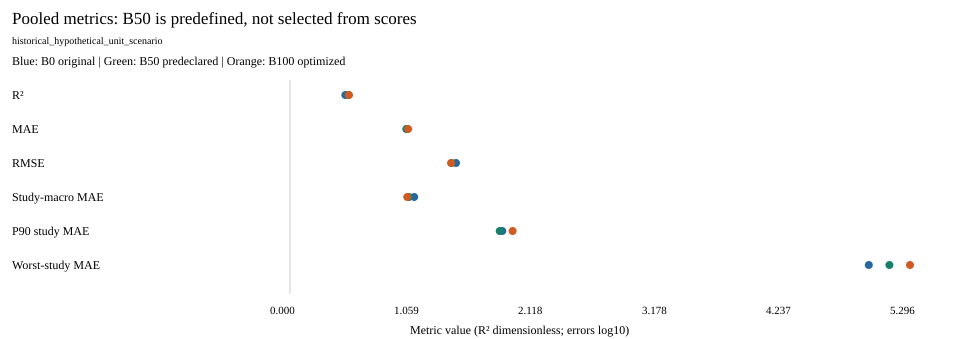

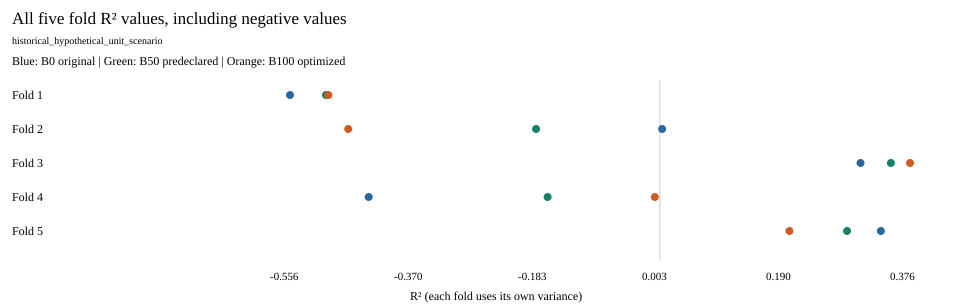

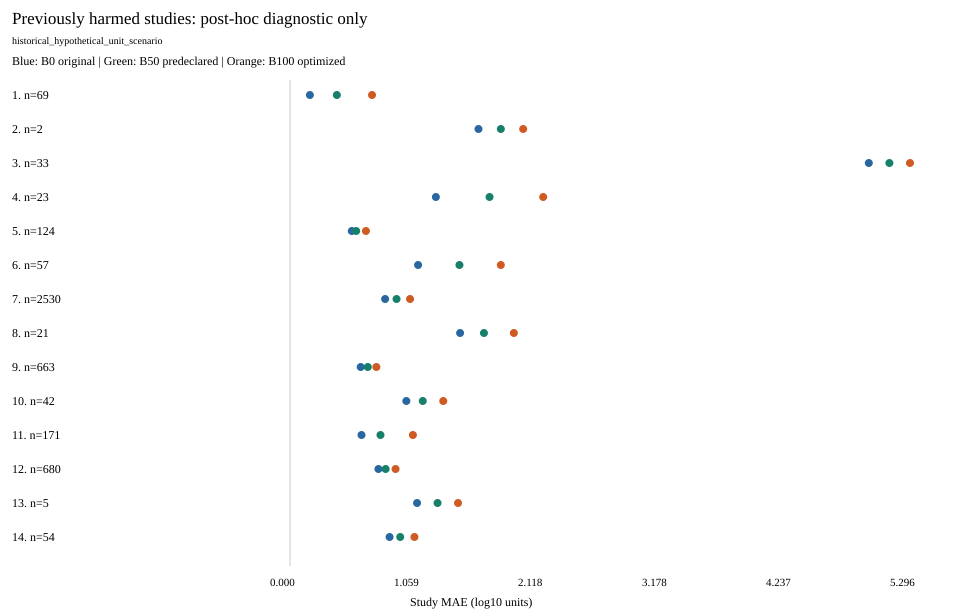

Input, source, configuration, split and environment identity saved. No model checkpoints reused.


In [7]:
for path in make_figures(analysis):display(SVG(filename=str(path)))
analysis.checkpoint_identity()
print('Input, source, configuration, split and environment identity saved. No model checkpoints reused.')

## 8. Unit/integration tests and final protected-file verification

In [8]:
test_status=run_suite(analysis)
assert blocked_fit.call_count==0
print(json.dumps(test_status,indent=2))
print('All protected original, reproduction and optimization files remain unchanged.')

test_alignment_and_negative_controls (test_blending.BlendingTests.test_alignment_and_negative_controls) ... ok
test_all_per_fold_and_study_metrics (test_blending.BlendingTests.test_all_per_fold_and_study_metrics) ... ok
test_budget_fail_closed_no_new_lightgbm_fits (test_blending.BlendingTests.test_budget_fail_closed_no_new_lightgbm_fits) ... ok
test_checkpoint_identity_and_input_hashes (test_blending.BlendingTests.test_checkpoint_identity_and_input_hashes) ... ok
test_endpoint_equivalence_and_convex_arithmetic (test_blending.BlendingTests.test_endpoint_equivalence_and_convex_arithmetic) ... ok
test_factor_ten_offset_boundary_inclusive (test_blending.BlendingTests.test_factor_ten_offset_boundary_inclusive) ... ok
test_gate_predicates_and_failure_controls (test_blending.BlendingTests.test_gate_predicates_and_failure_controls) ... ok
test_import_is_side_effect_free_and_deterministic (test_blending.BlendingTests.test_import_is_side_effect_free_and_deterministic) ... ok
test_independent_agg

## 9. Report rendering and stop

In [9]:
report_text=compose_report(analysis,test_status,9)
(OUT/'checkpoints/report_ready.md').write_text(report_text)
display(Markdown(report_text))
print('All analysis complete. Runner saves the executed notebook, status and final report, then stops.')
assert blocked_fit.call_count==0
fit_guard.stop()

# Fixed LightGBM blending and study robustness

**Scenario: `historical_hypothetical_unit_scenario` for every result.** Historical ×10^6 multipliers for Barrows (1,389 rows) and Dehm (81 rows) are **unverified hypotheses**, not certified corrections. All predictions and errors use `log10(concentration + 0.001)`; they are not certified estimates of true synthetic-only marine microplastic concentration.

## Result and decision

The fixed original and optimized references remain **0.4726308398591973** and **0.5033812847921568** pooled R². The predeclared 50/50 blend is **0.5003245744653094** (Δ versus original **+0.0276937346061121**, versus optimized **-0.0030567103268474**).

The predefined B50 does not meet the full reliability screen. Preserve both immutable references and stop; do not promote a blend or tune weights to rescue the result.

B50 pooled MAE is **0.994331165**, study-macro MAE **1.016215256**, p90 study MAE **1.791308098**, worst-study MAE **5.119885506**, and within-one-log fraction **0.630386155 (63.04%)**. All reference contrasts, including deteriorations, follow below. R² is not a percentage of correct predictions. Within-one-log is a factor-ten tolerance on **concentration plus 0.001**, not plain concentration.

## Stage A: five fixed combinations, zero fits

The registry was written to `predeclared_plan.json` before calculating blend outcomes. B50 is the **predeclared main candidate**, not the highest outer-score candidate selected after seeing results. B25/B75 are retrospective fixed-weight sensitivity analyses, not a weight search or a leaderboard winner. Each weight is constant across all rows and studies, nonnegative, and sums with its original-model weight to one. Blending occurs on the common log10 prediction scale, not on raw concentrations.

| blend | weight_optimized | R2 | MAE | RMSE | study_macro_MAE | study_macro_MSE | median_study_MAE | p90_study_MAE | worst_study_MAE | within_1_log | mean_fold_R2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| B0 | 0.000000000 | 0.472630840 | 0.996377423 | 1.418197731 | 1.060942164 | 2.171751369 | 0.866894949 | 1.813391314 | 4.943934893 | 0.639392512 | -0.071234992 |
| B25 | 0.250000000 | 0.489557335 | 0.992964769 | 1.395252808 | 1.035630043 | 2.093719287 | 0.851638786 | 1.701597238 | 5.031910199 | 0.632799623 | -0.050805750 |
| B50 | 0.500000000 | 0.500324574 | 0.994331165 | 1.380458696 | 1.016215256 | 2.044095862 | 0.853914876 | 1.791308098 | 5.119885506 | 0.630386155 | -0.045569542 |
| B75 | 0.750000000 | 0.504932558 | 0.999807376 | 1.374078691 | 1.003910132 | 2.022881093 | 0.860505669 | 1.889565289 | 5.207860812 | 0.619613845 | -0.055526369 |
| B100 | 1.000000000 | 0.503381285 | 1.009342570 | 1.376229816 | 1.001411331 | 2.030074980 | 0.831673076 | 1.901217782 | 5.295836118 | 0.610077702 | -0.080676231 |

### Main candidate versus both immutable references

| metric | B0_original | B50_main | B100_optimized | B50_minus_B0 | B50_minus_B100 |
| --- | --- | --- | --- | --- | --- |
| R2 | 0.472630840 | 0.500324574 | 0.503381285 | 0.027693735 | -0.003056710 |
| MAE | 0.996377423 | 0.994331165 | 1.009342570 | -0.002046259 | -0.015011406 |
| RMSE | 1.418197731 | 1.380458696 | 1.376229816 | -0.037739034 | 0.004228881 |
| study_macro_MAE | 1.060942164 | 1.016215256 | 1.001411331 | -0.044726908 | 0.014803925 |
| study_macro_MSE | 2.171751369 | 2.044095862 | 2.030074980 | -0.127655507 | 0.014020882 |
| median_study_MAE | 0.866894949 | 0.853914876 | 0.831673076 | -0.012980074 | 0.022241799 |
| p90_study_MAE | 1.813391314 | 1.791308098 | 1.901217782 | -0.022083216 | -0.109909685 |
| worst_study_MAE | 4.943934893 | 5.119885506 | 5.295836118 | 0.175950612 | -0.175950612 |
| within_1_log | 0.639392512 | 0.630386155 | 0.610077702 | -0.009006357 | 0.020308453 |
| mean_fold_R2 | -0.071234992 | -0.045569542 | -0.080676231 | 0.025665450 | 0.035106689 |

Full-precision changes for every blend relative to **both** references are saved in every paired metric CSV. Positive error changes mean deterioration; positive R²/coverage changes mean improvement. Study quantiles use linear interpolation. Pooled R² scores all 16,988 held-out predictions together; arithmetic mean fold R² is a separate quantity.

## Stage B: precommitted cost-control gate

**FAIL.** The required stop rule applies. Failed conditions: study_macro_MAE_does_not_increase. No alternative weight was searched to rescue the gate.

| condition | passed |
| --- | --- |
| R2_loss_no_more_than_0.015 | True |
| study_macro_MAE_does_not_increase | False |
| at_least_two_weaknesses_improve | True |
| worst_study_MAE_increase_at_most_0.10 | True |
| no_integrity_issue | True |

Improvement checks among pooled MAE, p90 study MAE and within-one-log coverage: `{"pooled_MAE": true, "p90_study_MAE": true, "within_1_log": true}`. Exact B50-minus-B100 deltas are in `stage_b_gate.json`. No outer labels fit coefficients or choose weights; labels are used only to score the fixed blends and apply the explicitly requested cost-control gate. That gate is itself retrospective and must not be treated as independent confirmation.

## Stage C: conditional training-only blend selection

**Not run: Stage B failed.** No Stage C fit was authorized or started. Nested parameter/weight selection and its label-independence tests are not claimed as completed. The existing original/optimized validation splits were audited, but no new nesting was needed.

**New LightGBM fits: 0.** No prior phase was restarted; none of its 127 fits was repeated. `fit_log.jsonl` contains a not-run decision event, not a fit start. No stacking, learned gate, support estimate, new features, target changes, data acquisition, chronological-score consultation, or deployable model was used.

## All outer folds and post-hoc folds 2/5 diagnostic

| fold | blend | rows | studies | R2 | MAE | RMSE | delta_vs_B0__MAE | delta_vs_B100__MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | B0 | 6135 | 1 | -0.555995934 | 0.727918876 | 0.909011644 | 0.000000000 | 0.008745402 |
| 1 | B50 | 6135 | 1 | -0.501874592 | 0.718444641 | 0.893062910 | -0.009474235 | -0.000728833 |
| 1 | B100 | 6135 | 1 | -0.498304099 | 0.719173475 | 0.892000713 | -0.008745402 | 0.000000000 |
| 2 | B0 | 2714 | 11 | 0.003501738 | 0.812758445 | 1.003800108 | 0.000000000 | -0.189714495 |
| 2 | B50 | 2714 | 11 | -0.186045480 | 0.898581868 | 1.095114771 | 0.085823423 | -0.103891072 |
| 2 | B100 | 2714 | 11 | -0.468473655 | 1.002472940 | 1.218546327 | 0.189714495 | 0.000000000 |
| 3 | B0 | 2712 | 20 | 0.301706051 | 1.602671579 | 2.273102127 | 0.000000000 | 0.005960123 |
| 3 | B50 | 2712 | 20 | 0.347360915 | 1.587249250 | 2.197537771 | -0.015422329 | -0.009462206 |
| 3 | B100 | 2712 | 20 | 0.376104003 | 1.596711456 | 2.148601668 | -0.005960123 | 0.000000000 |
| 4 | B0 | 2714 | 20 | -0.437682635 | 1.275470188 | 1.739840234 | 0.000000000 | 0.208724211 |
| 4 | B50 | 2714 | 20 | -0.168734394 | 1.162467976 | 1.568685089 | -0.113002212 | 0.095721999 |
| 4 | B100 | 2714 | 20 | -0.007517498 | 1.066745978 | 1.456478757 | -0.208724211 | 0.000000000 |
| 5 | B0 | 2713 | 20 | 0.332295820 | 0.901872291 | 1.234620532 | 0.000000000 | -0.125934823 |
| 5 | B50 | 2713 | 20 | 0.281445841 | 0.953089092 | 1.280770162 | 0.051216801 | -0.074718022 |
| 5 | B100 | 2713 | 20 | 0.194810093 | 1.027807115 | 1.355784325 | 0.125934823 | 0.000000000 |

Folds 2 and 5 were singled out by the preceding optimization results, not by this blend. Their diagnostics do not enter weights or the screening rule. `folds_2_and_5_diagnostic.csv` includes all five fixed combinations. The first outer fold contains a single 6,135-row study (36.11% of all observations); it is retained. Negative R² values are neither clipped nor omitted.

## Study-level robustness and harms

| comparison | studies_MAE_worse | studies_MAE_worse_by_over_0.10 | studies_MAE_better | studies_MAE_equal |
| --- | --- | --- | --- | --- |
| B50 vs B0 | 27 | 9 | 45 | 0 |
| B50 vs B100 | 37 | 18 | 35 | 0 |

All **72 studies**, including difficult and very small studies (minimum **2 rows**), are retained. Study MAE/MSE do not require within-study target variance. We report these well-defined errors rather than within-study R²; no observations are removed. Synthetic singleton cases are tested, but there are no one-row study groups in this dataset. Macro metrics average each study equally. The following 14 studies were previously harmed by >0.10 log10 MAE under optimization; membership is copied from the protected prior table and used **only for description**:

| study | rows | fold | B0 | B50 | B100 | B50_minus_B0 | B50_minus_B100 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| https://doi.org/10.1016/j.chemosphere.2022.133980 | 69 | 4 | 0.169873212 | 0.400181589 | 0.700700749 | 0.230308377 | -0.300519160 |
| https://doi.org/10.1016/j.marpolbul.2022.114452 | 2 | 3 | 1.610055177 | 1.800952420 | 1.991849663 | 0.190897243 | -0.190897243 |
| https://doi.org/10.1016/j.marpolbul.2024.117288 | 33 | 5 | 4.943934893 | 5.119885506 | 5.295836118 | 0.175950612 | -0.175950612 |
| https://doi.org/10.1016/j.scitotenv.2018.12.192 | 23 | 4 | 1.246062535 | 1.704509198 | 2.162955861 | 0.458446663 | -0.458446663 |
| https://doi.org/10.1016/j.scitotenv.2022.155958 | 124 | 3 | 0.527637872 | 0.565486929 | 0.648682630 | 0.037849057 | -0.083195700 |
| https://doi.org/10.1016/j.scitotenv.2022.156259 | 57 | 5 | 1.094196391 | 1.447439523 | 1.800682654 | 0.353243131 | -0.353243131 |
| https://doi.org/10.1021/es4053076 | 2530 | 2 | 0.812465081 | 0.909980035 | 1.025262569 | 0.097514953 | -0.115282535 |
| https://doi.org/10.1038/srep14947 | 21 | 5 | 1.452892293 | 1.656613412 | 1.912144079 | 0.203721119 | -0.255530667 |
| https://doi.org/10.1088/1748-9326/abbb4f | 663 | 5 | 0.603654884 | 0.664562405 | 0.737806239 | 0.060907521 | -0.073243835 |
| https://doi.org/10.1126/sciadv.1600582 | 42 | 5 | 0.993794437 | 1.134044943 | 1.309195670 | 0.140250505 | -0.175150728 |
| https://doi.org/10.1371/journal.pone.0080466 | 171 | 5 | 0.610816427 | 0.772880407 | 1.049821295 | 0.162063980 | -0.276940889 |
| https://doi.org/10.1371/journal.pone.0111913 | 680 | 5 | 0.755330368 | 0.816789818 | 0.901634553 | 0.061459450 | -0.084844735 |
| https://doi.org/10.3389/fenvs.2021.719274 | 5 | 2 | 1.085333105 | 1.260261078 | 1.435189051 | 0.174927973 | -0.174927973 |
| https://doi.org/10.3389/fmars.2021.626026 | 54 | 5 | 0.850583078 | 0.941432293 | 1.062903851 | 0.090849216 | -0.121471557 |

Ten largest B50 MAE increases relative to the original (full 360 blend-study rows in `paired_study_metrics.csv`):

| study | rows | fold | MAE | delta_vs_B0__MAE | delta_vs_B100__MAE |
| --- | --- | --- | --- | --- | --- |
| https://doi.org/10.1016/j.scitotenv.2018.12.192 | 23 | 4 | 1.704509198 | 0.458446663 | -0.458446663 |
| https://doi.org/10.1016/j.scitotenv.2022.156259 | 57 | 5 | 1.447439523 | 0.353243131 | -0.353243131 |
| https://doi.org/10.1016/j.chemosphere.2022.133980 | 69 | 4 | 0.400181589 | 0.230308377 | -0.300519160 |
| https://doi.org/10.1038/srep14947 | 21 | 5 | 1.656613412 | 0.203721119 | -0.255530667 |
| https://doi.org/10.1016/j.marpolbul.2022.114452 | 2 | 3 | 1.800952420 | 0.190897243 | -0.190897243 |
| https://doi.org/10.1016/j.marpolbul.2024.117288 | 33 | 5 | 5.119885506 | 0.175950612 | -0.175950612 |
| https://doi.org/10.3389/fenvs.2021.719274 | 5 | 2 | 1.260261078 | 0.174927973 | -0.174927973 |
| https://doi.org/10.1371/journal.pone.0080466 | 171 | 5 | 0.772880407 | 0.162063980 | -0.276940889 |
| https://doi.org/10.1126/sciadv.1600582 | 42 | 5 | 1.134044943 | 0.140250505 | -0.175150728 |
| https://doi.org/10.1021/es4053076 | 2530 | 2 | 0.909980035 | 0.097514953 | -0.115282535 |

No harmed-study flag, study identity, fold ID, sample outcome, or test-specific threshold is a predictor or a blend weight.

## Method family and study-size diagnostics

| grouping | group | blend | rows | studies | R2 | MAE | study_macro_MAE | p90_study_MAE | within_1_log |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| method_family | bulk water | B0 | 1903 | 12 | -0.041714274 | 2.053115055 | 1.383763865 | 2.199928607 | 0.377299002 |
| method_family | bulk water | B50 | 1903 | 12 | -0.007025341 | 2.092728220 | 1.424679880 | 2.511637380 | 0.312664214 |
| method_family | bulk water | B100 | 1903 | 12 | 0.002651624 | 2.161275272 | 1.513184163 | 2.826229246 | 0.262217551 |
| method_family | pump | B0 | 852 | 6 | -1.331179300 | 1.299307102 | 1.228085517 | 1.527222784 | 0.392018779 |
| method_family | pump | B50 | 852 | 6 | -0.910240682 | 1.160103315 | 1.188666789 | 1.425969649 | 0.498826291 |
| method_family | pump | B100 | 852 | 6 | -0.642242876 | 1.034806607 | 1.177424939 | 1.443239446 | 0.598591549 |
| method_family | surface net | B0 | 14233 | 58 | 0.093209788 | 0.836954406 | 1.010207401 | 1.575413518 | 0.689243308 |
| method_family | surface net | B50 | 14233 | 58 | 0.141289566 | 0.837548514 | 0.947699592 | 1.591752266 | 0.680741938 |
| method_family | surface net | B100 | 14233 | 58 | 0.132729674 | 0.853800991 | 0.910459334 | 1.511692013 | 0.657275346 |
| study_size_bin | 1-50 | B0 | 893 | 42 | 0.045598353 | 1.046319939 | 1.025915555 | 1.594338889 | 0.593505039 |
| study_size_bin | 1-50 | B50 | 893 | 42 | 0.079405838 | 0.994262493 | 0.957556610 | 1.699719620 | 0.637178052 |
| study_size_bin | 1-50 | B100 | 893 | 42 | 0.070826031 | 0.963188909 | 0.914500515 | 1.900163406 | 0.679731243 |
| study_size_bin | 1001+ | B0 | 11199 | 4 | 0.500489932 | 0.976626555 | 1.236195130 | 1.870315309 | 0.660416109 |
| study_size_bin | 1001+ | B50 | 11199 | 4 | 0.531718087 | 0.982140059 | 1.228348427 | 1.850719592 | 0.638628449 |
| study_size_bin | 1001+ | B100 | 11199 | 4 | 0.539887949 | 1.000912949 | 1.235661474 | 1.860288559 | 0.607286365 |
| study_size_bin | 201-1000 | B0 | 3140 | 7 | 0.153244943 | 1.062557264 | 1.234032372 | 1.941764023 | 0.566878981 |
| study_size_bin | 201-1000 | B50 | 3140 | 7 | 0.174370358 | 1.051174276 | 1.214241839 | 1.825749116 | 0.581528662 |
| study_size_bin | 201-1000 | B100 | 3140 | 7 | 0.162146089 | 1.049044504 | 1.201645073 | 1.785037544 | 0.585350318 |
| study_size_bin | 51-200 | B0 | 1756 | 19 | 0.294116574 | 0.978602140 | 1.037703967 | 1.838501709 | 0.658314351 |
| study_size_bin | 51-200 | B50 | 1756 | 19 | 0.325389371 | 0.970471337 | 1.028264960 | 1.644292774 | 0.661731207 |
| study_size_bin | 51-200 | B100 | 1756 | 19 | 0.311637680 | 1.015580880 | 1.070443832 | 1.801122346 | 0.636674260 |

The complete CSV also includes B25/B75 and every metric/delta. Study-size bins remain 1–50, 51–200, 201–1000 and 1001+ eligible rows; no target bins. Family slices are row-based, so a study can contribute to several method families. Every grouping covers all 16,988 rows for each blend. Rows and studies are explicitly counted.

## Integrity, precision, execution and tests

- Exact 16,988 modelling rows, 72 linked DOI/accession studies, original 29,076-row dataset, original source-row order, folds and target values preserved. Test sizes **6,135 / 2,714 / 2,712 / 2,714 / 2,713**. Each row has exactly one outer OOF prediction. No silent joins, NaN dropping, imputation of predictions or unsupported-row exclusions.
- The baseline OOF file has no scenario column; its scenario is established from the frozen original source, saved historical unit adjustments and exact target equality, then explicitly labeled here. The optimized file already carries the same scenario.
- Existing input manifests, source/configuration/split identities and artifact checksums were verified before analysis. CSVs were read with `float_precision='round_trip'`. Every original and optimized reference aggregate was recomputed; maximum absolute difference **0**, under `atol=rtol=1e-12`. Full differences: `reference_metric_audit.csv`. Raw-scale baseline metrics were checked only as preservation diagnostics, never compared with a different target scenario.
- Original preprocessing and study grouping were reconstructed by read-only calls to the prior loader, never its training routines. The original median/scaler/encoder/clipping behavior was checked on all five outer and 15 original inner training partitions, including missing numeric values and unseen categories. These are preprocessing tests, **not LightGBM training**.
- **18 unit/integration tests passed**, **46 additional data/audit assertions passed**, no failures. Tests include deliberately mismatched rows/labels/scenarios, missing predictions, independent metric recomputation, fixed-weight target perturbation, all-case evaluation, factor-ten boundaries, original preprocessing, split disjointness, deterministic arithmetic, import-with-no-fit enforcement, budget blocking, identity invalidation and protected-file hashes. `tests.txt` records what actually ran. Actual Stage C model/weight fitting was not run and its learned-selection invariance is not claimed.
- The initial preparation run exposed two incorrect test assumptions: it expected a real singleton study and hard-coded 29 reference-audit rows instead of the actual 27. The tests were repaired to verify complete group membership and derive the audit count from the metric schema; singleton behavior is covered synthetically. No data, folds, weights, metrics or gate thresholds were changed. The subsequent full fresh-kernel execution passed. The initial failure log remains in `preparation_execution.log`.
- **9 notebook code cells executed** in order in a fresh kernel; cell statuses and output types are captured in `notebook_execution_status.json`. Every cell uses the same importable modules as the CLI. LightGBM `fit` is patched to fail during this zero-fit run and tests, preventing accidental prior-phase execution.
- Environment: Python 3.12.7, macOS-15.6.1-arm64-arm-64bit; packages `{"ipykernel": "7.4.0", "lightgbm": "4.7.0", "nbclient": "0.11.0", "nbformat": "5.11.1", "numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1"}`. Seed 0 documented; fixed arithmetic is deterministic and does not use randomness. CPU/thread cap 4, no downloads. Runtime/IPython/cache files are isolated under `blending_outputs/`.
- `integrity_manifest.json` records before/after SHA-256 values for **every pre-existing file**, including the raw data, original source, `.git/`, and complete reproduction/optimization directories. Symlinks are recorded as link targets without following external interpreters. **All protected files remain unchanged.** The newly supplied prompt inside `optimization_outputs/` is also protected.
- No new model checkpoints exist. `checkpoints/analysis_identity.json` keys the zero-fit analysis to input/data hashes, all analysis/test source, frozen plan/configuration, split identities and versions. Reruns verify protected references and recompute cheap arithmetic; they never use incompatible model predictions or start training.

## Reproduce (from the repository root)

```sh
PYTHONDONTWRITEBYTECODE=1 reproduction_outputs/venv/bin/python blending_outputs/source/run.py --prepare
PYTHONDONTWRITEBYTECODE=1 reproduction_outputs/venv/bin/python blending_outputs/source/run.py
```

The first command executes the notebook and all tests without creating the final report; the second executes the same zero-fit analysis and writes this report **last**. These commands do not restart earlier experiments. Sources are importable and have no side-effect execution on import. All new outputs are confined to `blending_outputs/`.

## Outputs and limitations

- `LightGBM_Blend_Research_EXECUTED.ipynb`, `aligned_oof_predictions.csv`.
- `fixed_blend_metrics.csv`, `paired_fold_metrics.csv`, `paired_study_metrics.csv`, `method_and_study_size_metrics.csv`.
- `stage_b_gate.json`, `stage_c_status.json`, `final_status.json`, `tests.txt`, `fit_log.jsonl`, `environment.json`, `integrity_manifest.json`.
- `figures/pooled_metrics.svg`, `figures/fold_r2.svg`, `figures/prior_harmed_studies.svg`; extra diagnostic row keys and tables accompany these.

The five outer folds and outcomes have already been inspected, including before this phase. This analysis is **exploratory on reused historical-scenario targets**, not an independent holdout, prospective test, certified physical prediction, production-readiness assessment, or proof of new-study generalization. Neither a higher R² nor passing the cost-control gate removes these limitations. No reference is overwritten or promoted.

**Stop: the requested bounded experiment ends with this report. No further phase is started.**


All analysis complete. Runner saves the executed notebook, status and final report, then stops.


False